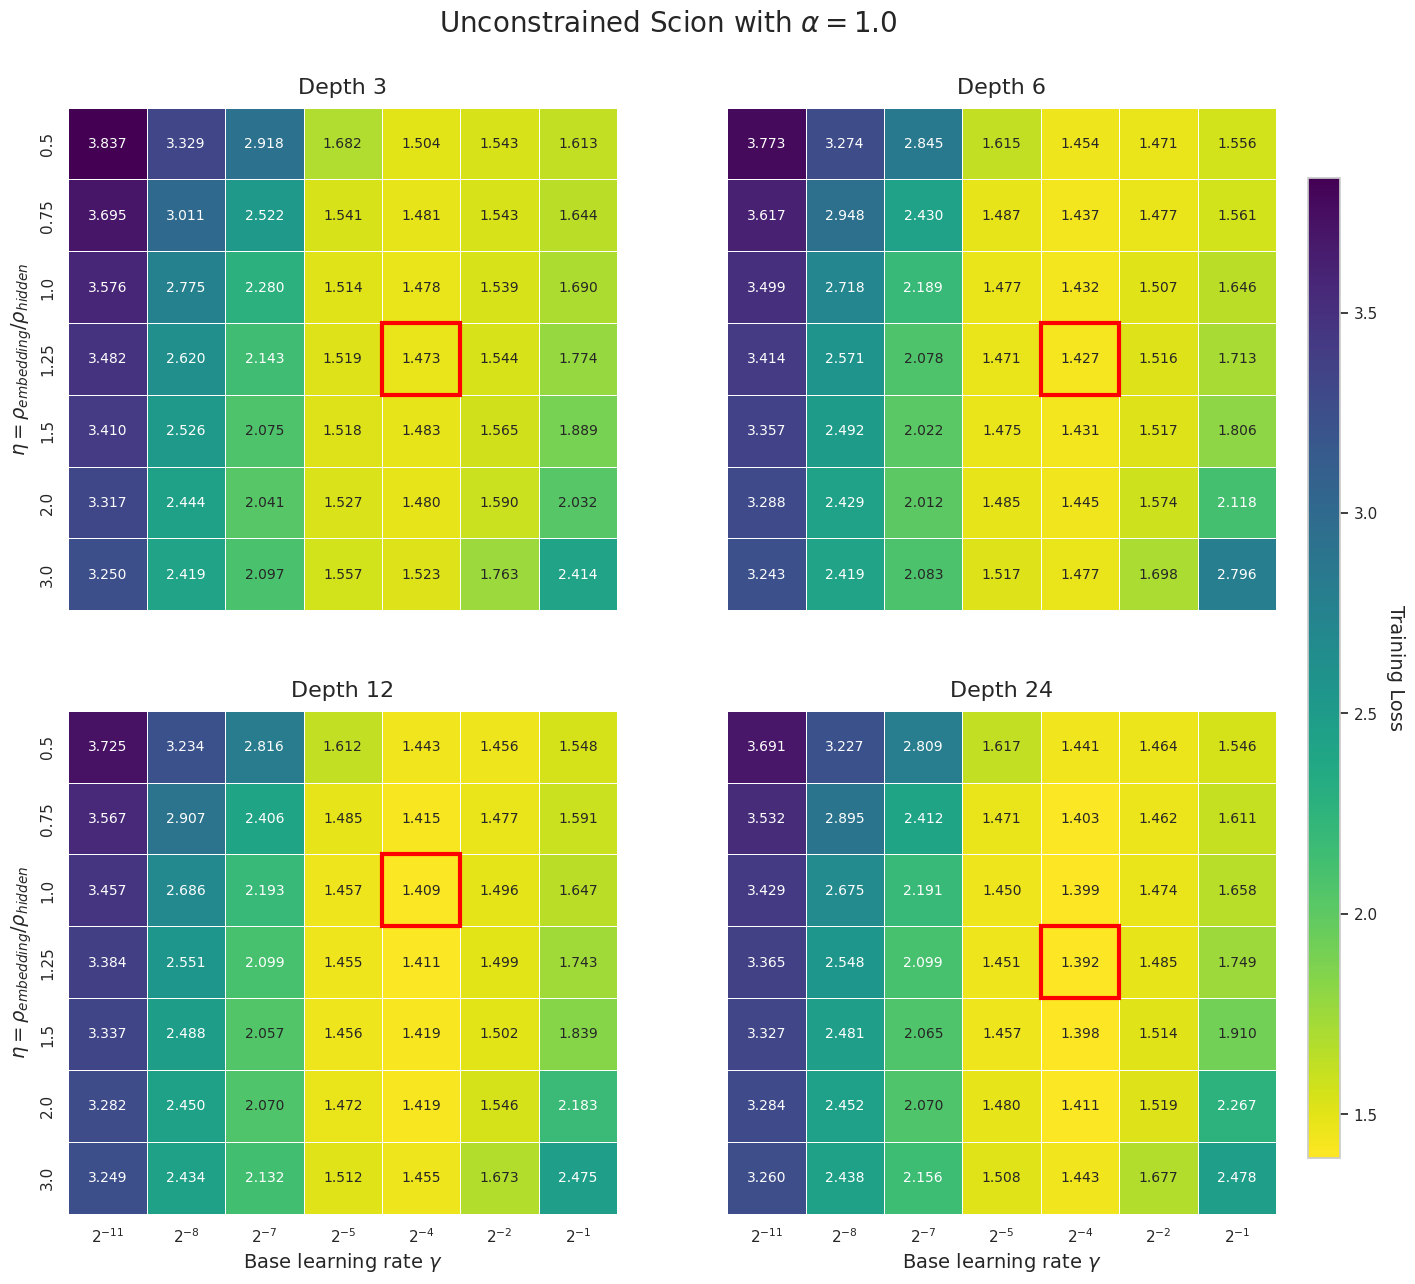

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as patches

# --- Settings ---
sns.set(style='whitegrid')
dataset = 'shakespeare_char'
scion_method = 'unconstrained_scion' 
loss_dataset = 'train'
alpha = 1.0
epochs = 122
rh = 3.0 
depths = [3, 6, 12, 24]
seeds = [1]
widths = [256]
rhos = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 3.0]
lrs = ['6e-4', '3e-3', '6e-3', '3e-2', '6e-2', '3e-1', '6e-1']

lr_labels = [f"$2^{{{int(np.round(np.log2(float(lr))) )}}}$" for lr in lrs]

all_heatmap_data = {}
for depth in depths:
    heatmap_means = np.full((len(rhos), len(lrs)), np.nan)
    for r_idx, rho in enumerate(rhos):
        re = rho * rh
        for l_idx, lr in enumerate(lrs):
            losses = []
            for seed in seeds:
                for width in widths:
                    out_path = f'alpha_skipconnection_{alpha}_first_layerSpectral_width{width}_depth{depth}_rho{rho}_rh{rh}_re{re}0_seed{seed}_lr{lr}_epochs{epochs}'
                    csv_path = os.path.join(f'radius_transfer/{dataset}/{scion_method}/out_{epochs}_epochs/radius_hidden_{rh}', out_path, 'log.csv')
                    
                    if os.path.exists(csv_path):
                        try:
                            df = pd.read_csv(csv_path)
                            losses.append(df[f'{loss_dataset}/loss'].values[-1])
                        except: pass
            if losses:
                heatmap_means[r_idx, l_idx] = np.mean(losses)
    all_heatmap_data[depth] = heatmap_means

fig, axes = plt.subplots(2, 2, figsize=(16, 14), sharex=True, sharey=True)
axs = axes.flatten()
ims = []


all_vals = np.concatenate([v.flatten() for v in all_heatmap_data.values()])
vmin, vmax = np.nanmin(all_vals), np.nanmax(all_vals)

for idx, depth in enumerate(depths):
    ax = axs[idx]
    data = all_heatmap_data[depth]
    
    sns_ax = sns.heatmap(
        data,
        annot=True,
        fmt=".3f",
        linewidths=0.5,
        cmap="viridis_r",
        cbar=False,
        vmin=vmin, vmax=vmax, # Ensure consistent color scale
        annot_kws={"size": 10},
        ax=ax,
        xticklabels=lr_labels,
        yticklabels=rhos
    )
    ims.append(ax.collections[0])

    # highlight the best cell
    if not np.all(np.isnan(data)):
        opt_row, opt_col = np.unravel_index(np.nanargmin(data), data.shape)
        ax.add_patch(patches.Rectangle((opt_col, opt_row), 1, 1, fill=False, edgecolor="red", linewidth=3, clip_on=False))

    ax.set_title(f"Depth {depth}", fontsize=16, pad=10)
    
    # axis label
    if idx % 2 == 0:
        ax.set_ylabel(r"$\eta = \rho_{embedding} / \rho_{hidden}$", fontsize=14)
    if idx >= 2:
        ax.set_xlabel(r"Base learning rate $\gamma$", fontsize=14)


fig.subplots_adjust(right=0.88, top=0.90)
cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7]) 
cbar = fig.colorbar(ims[0], cax=cbar_ax)
cbar.set_label(f'Training Loss', rotation=270, labelpad=20, fontsize=14)

plt.suptitle(f"Unconstrained Scion with $\\alpha={alpha}$", 
             fontsize=20, y=0.97)

plt.savefig(f"grid_heatmap_{dataset}_{scion_method}_alpha_{alpha}_all_depth.pdf", bbox_inches='tight')
plt.show()